In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/student_scores.csv')
print("DataSet Loded")

DataSet Loded


In [ ]:
df.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


In [ ]:
df.shape

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   25 non-null     float64
 1   Scores  25 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 532.0 bytes


In [ ]:
df.describe()

,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000


In [ ]:
df.isnull().sum()

,0
Hours,0
Scores,0


In [ ]:
df['Hours'] = df['Hours'].apply(np.floor)
df

,Hours,Scores
0,2.0,21
1,5.0,47
2,3.0,27
3,8.0,75
4,3.0,30
5,1.0,20
6,9.0,88
7,5.0,60
8,8.0,81
9,2.0,25


In [ ]:
Q1 = df['Hours'].quantile(0.25)
Q3 = df['Hours'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_present = ((df['Hours'] < lower_bound) | (df['Hours'] > upper_bound)).any()

if outliers_present:
  print("Outliers are present")
else:
  print("Outliers are not present")

Outliers are not present


In [ ]:
x = df.drop('Scores', axis=1)
print("Feature matrix x created by dropping the 'Scores' column.")
x

,Hours
0,2.0
1,5.0
2,3.0
3,8.0
4,3.0
5,1.0
6,9.0
7,5.0
8,8.0
9,2.0


In [ ]:
y = df.iloc[:,-1]
y

,Scores
0,21
1,47
2,27
3,75
4,30
5,20
6,88
7,60
8,81
9,25


In [ ]:
#split the training into training and testing
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
#create the model
model = LinearRegression()

In [ ]:
#train the model
model.fit(x_train, y_train)
print("Model trained")

Model trained


In [ ]:
#generate pedictions for traning ans testing datasets usong the trained model
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)
print("Predictions generated for both training and testing")

Predictions generated for both training and testing


In [ ]:
#Evaluation using different merics for training
print('Model Evaluation Metrics:')
print('Mean Absolute Error (MAE):', mean_absolute_error(y_train, y_pred_train))
print('Mean Squared Error (MSE):', mean_squared_error(y_train, y_pred_train))
print('Root Mean Squared Error (RMSE):', np.sqrt(mean_squared_error(y_train, y_pred_train)))
print('R-squared (R2) Score:', r2_score(y_train, y_pred_train))

Model Evaluation Metrics:
Mean Absolute Error (MAE): 5.928731492597039
Mean Squared Error (MSE): 45.49707883153261
Root Mean Squared Error (RMSE): 6.745152246727468
R-squared (R2) Score: 0.9264072225329145


In [ ]:
#Evaluation using different merics for testing
print('Model Evaluation Metrics:')
print('Mean Absolute Error (MAE):', mean_absolute_error(y_test, y_pred_test))
print('Mean Squared Error (MSE):', mean_squared_error(y_test, y_pred_test))
print('Root Mean Squared Error (RMSE):', np.sqrt(mean_squared_error(y_test, y_pred_test)))
print('R-squared (R2) Score:', r2_score(y_test, y_pred_test))

Model Evaluation Metrics:
Mean Absolute Error (MAE): 5.806642657062824
Mean Squared Error (MSE): 40.66173779635896
Root Mean Squared Error (RMSE): 6.376655690591971
R-squared (R2) Score: 0.9308943953155014


In [ ]:
#slope
model.coef_

array([9.57462985])

In [ ]:
#intercept
model.intercept_

np.float64(8.242897158863528)

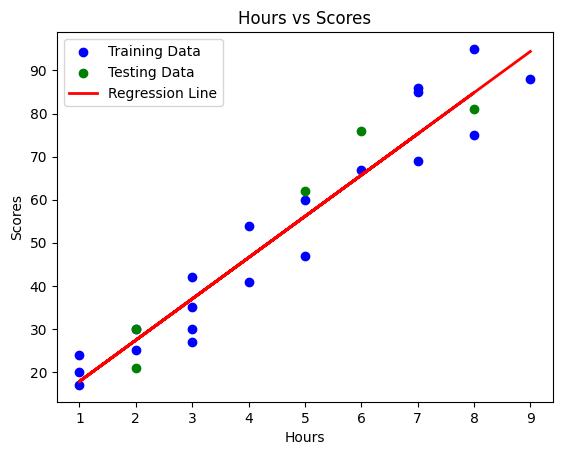

In [ ]:
#visualization
plt.scatter(x_train, y_train, color='blue', label='Training Data')
plt.scatter(x_test, y_test, color='green', label='Testing Data')
plt.plot(x_train, model.predict(x_train), color='red', linewidth=2, label='Regression Line')
plt.xlabel('Hours')
plt.ylabel('Scores')
plt.title('Hours vs Scores')
plt.legend()
plt.show()